# 3장 실습. 확률 보정

「확신 0.9」라는 말이 믿을 만하려면, 0.9 라고 말한 답들이 실제로 열에 아홉 맞아야 한다. 이 성질이 보정(calibration)이다. 이 노트북은 8장과 12장이 남긴 평가 기록을 읽어 보정을 손으로 잰다. 라이브러리 함수 하나로 끝내지 않고, 구간을 나누고 평균을 내고 차이를 더하는 과정을 표로 보인다.

| 절 | 내용 |
|---|---|
| 3.1 | 기록 읽기 — 확신과 정답 여부 |
| 3.2 | 구간을 나눠 ECE 를 손으로 |
| 3.3 | 신뢰도 도표 |
| 3.4 | 적절한 점수 — Brier 와 로그 손실 |
| 3.5 | 보정과 변별 — 늘 같은 확신을 내는 엔진 |
| 3.6 | 확신으로 줄 세우기 — 처리율과 오류율 |

GPU 도 API 키도 필요 없다. `results/eval_v1/` 에 8장의 `jev`·`tfidf-baseline` 기록과 12장의 `llm-gen`·`laya-routed` 기록이 있어야 한다.

In [1]:
import os, json, time, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
import koreanize_matplotlib  # noqa: F401
from dotenv import load_dotenv
from requests.adapters import HTTPAdapter, Retry

load_dotenv()
DATA, OUT = Path("data"), Path("out")
OUT.mkdir(exist_ok=True)
TASKS = ["topic", "entails", "positive", "similarity"]
COLOR = {"topic": "#2a78d6", "entails": "#eb6834", "positive": "#1baf7a", "similarity": "#eda100"}
pd.set_option("display.precision", 3)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
read_jsonl = lambda p: [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()]

def probs_of(answer):
    return answer.get("probabilities") or {"true": answer["noul"], "false": 1 - answer["noul"]}

def judge(item, resp):
    (task, q), = item["questions"].items()
    a = resp["answers"][task]
    pr = {str(k): float(v) for k, v in probs_of(a).items()}
    best = max(pr, key=pr.get)
    pred = {"noul": lambda: pr["true"] >= 0.5, "choice": lambda: best, "score": lambda: int(best)}[q["type"]]()
    return {"id": item["id"], "task": item["task"], "qtype": q["type"], "gold": item["gold"], "model": resp["model"],
            "pred": pred, "probs": pr, "conf": pr[best], "conf_field": a.get("confidence"), "correct": bool(pred == item["gold"]),
            "input_tokens": resp["usage"]["input_tokens"], "latency_s": resp["_latency_s"]}

def run(items, engine=lambda it: ask(it["state"], it["questions"]), workers=4):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(lambda it: judge(it, engine(it)), items))

arrays = lambda recs: (np.array([r["conf"] for r in recs]), np.array([r["correct"] for r in recs], float))

def ece(conf, ok, bins=15):
    idx = np.clip(np.searchsorted(np.linspace(0, 1, bins + 1), conf, side="left") - 1, 0, bins - 1)
    return float(sum(abs(conf[idx == i].mean() - ok[idx == i].mean()) * (idx == i).sum() for i in np.unique(idx)) / len(conf))

pd.set_option("display.float_format", "{:.4f}".format)
RESULTS = Path("results/eval_v1")
ENGINES = {"jev": "Jev", "llm-gen": "로컬 LLM (적은 확신)", "tfidf-baseline": "TF-IDF", "laya-routed": "Laya 기본"}
assert all((RESULTS / f"{n}.records.jsonl").exists() for n in ENGINES), "8장(nb08)과 12장(nb12)을 먼저 실행한다"
recs = {n: read_jsonl(RESULTS / f"{n}.records.jsonl") for n in ENGINES}
pd.DataFrame({ENGINES[n]: {"항목": len(rs), "정확도": arrays(rs)[1].mean(), "평균 확신": arrays(rs)[0].mean()} for n, rs in recs.items()}).T

,항목,정확도,평균 확신
Jev,800.0000,0.7438,0.8169
로컬 LLM (적은 확신),800.0000,0.6887,0.9629
TF-IDF,800.0000,0.6538,0.6801
Laya 기본,800.0000,0.5062,0.6794


## 3.1 기록 읽기

기록 한 줄에는 선택지마다의 확률(`probs`), 가장 큰 확률(`conf`), 그 답이 맞았는지(`correct`)가 있다. 보정을 재는 데는 `conf` 와 `correct` 두 열이면 된다.

In [2]:
pick = lambda rs, i: {k: rs[i][k] for k in ("id", "task", "gold", "pred", "conf", "correct")} | {"probs": {k: round(v, 3) for k, v in rs[i]["probs"].items()}}
pd.DataFrame([pick(recs["jev"], 0), pick(recs["llm-gen"], 0), pick(recs["jev"], 300), pick(recs["llm-gen"], 300)], index=["Jev", "로컬 LLM", "Jev", "로컬 LLM"])

,id,task,gold,pred,conf,correct,probs
Jev,ynat-v1_dev_04100,topic,경제,경제,1.0000,True,"{'IT과학': 0.0, '경제': 1.0, '사회': 0.0, '생활문화': 0...."
로컬 LLM,ynat-v1_dev_04100,topic,경제,경제,0.9500,True,"{'IT과학': 0.008, '경제': 0.95, '사회': 0.008, '생활문화..."
Jev,klue-nli-v1_dev_00413,entails,False,False,0.9500,True,"{'true': 0.05, 'false': 0.95}"
로컬 LLM,klue-nli-v1_dev_00413,entails,False,False,1.0000,True,"{'true': 0.0, 'false': 1.0}"


## 3.2 구간을 나눠 ECE 를 손으로

확신을 0~1 사이 같은 폭 10구간으로 나눈다. 구간마다 항목 수, 평균 확신, 정답률을 구하고, 평균 확신과 정답률의 차이에 그 구간의 항목 비율을 곱해 더한다. 그 합이 ECE(Expected Calibration Error)다.

In [3]:
def bin_table(rs, n_bins=10):
    conf, ok = arrays(rs)
    idx = np.clip((conf * n_bins).astype(int), 0, n_bins - 1)        # 0.9~1.0 은 마지막 구간에 넣는다
    rows = [{"구간": f"{b / n_bins:.1f}~{(b + 1) / n_bins:.1f}", "항목 수": int((idx == b).sum()), "평균 확신": conf[idx == b].mean(),
             "정답률": ok[idx == b].mean()} for b in np.unique(idx)]
    t = pd.DataFrame(rows)
    return t.assign(차이=(t["평균 확신"] - t["정답률"]).abs(), 가중치=t["항목 수"] / len(conf)).assign(기여=lambda d: d["차이"] * d["가중치"])

for n in ("jev", "llm-gen"):
    t = bin_table(recs[n])
    print(f"[{ENGINES[n]}]\n{t.to_string(index=False)}\nECE(10구간) = 기여의 합 = {t['기여'].sum():.3f}  | 8장 함수(15구간) = {ece(*arrays(recs[n])):.3f}\n")

[Jev]
     구간  항목 수  평균 확신    정답률     차이    가중치     기여
0.3~0.4     9 0.3678 0.3333 0.0344 0.0112 0.0004
0.4~0.5    34 0.4541 0.2059 0.2482 0.0425 0.0106
0.5~0.6    83 0.5493 0.3976 0.1517 0.1037 0.0157
0.6~0.7    93 0.6458 0.4409 0.2049 0.1163 0.0238
0.7~0.8    84 0.7464 0.5952 0.1512 0.1050 0.0159
0.8~0.9   115 0.8452 0.8087 0.0365 0.1437 0.0052
0.9~1.0   382 0.9666 0.9634 0.0032 0.4775 0.0015
ECE(10구간) = 기여의 합 = 0.073  | 8장 함수(15구간) = 0.073

[로컬 LLM (적은 확신)]
     구간  항목 수  평균 확신    정답률     차이    가중치     기여
0.1~0.2     1 0.1429 0.0000 0.1429 0.0013 0.0002
0.8~0.9    32 0.8484 0.4688 0.3797 0.0400 0.0152
0.9~1.0   767 0.9687 0.6988 0.2699 0.9587 0.2588
ECE(10구간) = 기여의 합 = 0.274  | 8장 함수(15구간) = 0.274



## 3.3 신뢰도 도표

구간마다 평균 확신(가로)과 정답률(세로)을 점으로 찍는다. 대각선 위에 있으면 보정된 것이다. 대각선 아래는 과신(말한 것보다 덜 맞음), 위는 과소 확신이다. 점의 크기는 그 구간의 항목 수다.

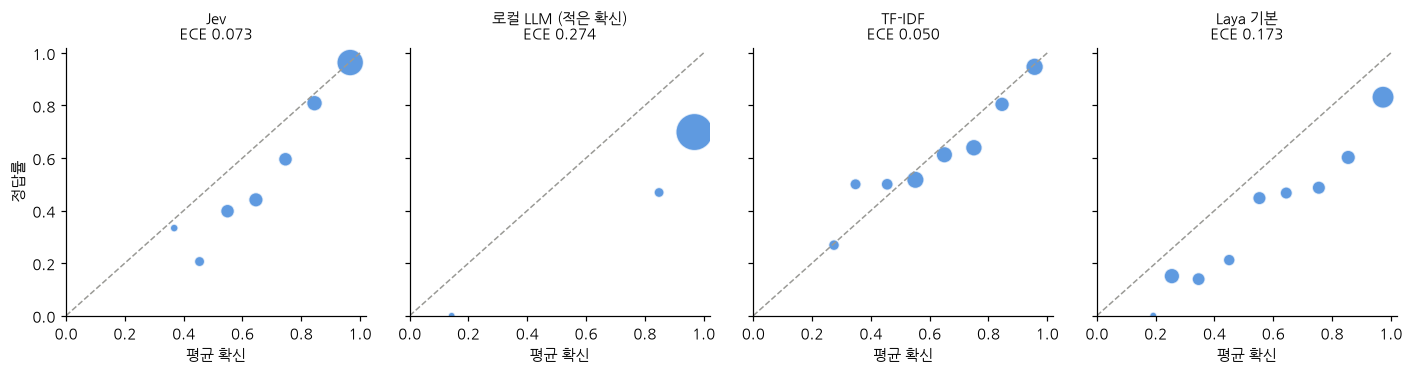

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.5), dpi=110, sharey=True)
for ax, (n, name) in zip(axes, ENGINES.items()):
    t = bin_table(recs[n])
    ax.plot([0, 1], [0, 1], ls="--", lw=1, color="#9a9a96")
    ax.scatter(t["평균 확신"], t["정답률"], s=20 + 600 * t["가중치"], color="#2a78d6", alpha=0.75, edgecolor="white")
    ax.set_title(f"{name}\nECE {t['기여'].sum():.3f}", fontsize=10); ax.set_xlabel("평균 확신"); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
axes[0].set_ylabel("정답률")
fig.tight_layout(); fig.savefig(OUT / "nb03_reliability.png", bbox_inches="tight"); plt.show()

## 3.4 적절한 점수: Brier 와 로그 손실

ECE 는 구간을 어떻게 나누느냐에 따라 값이 바뀐다. 구간 없이 항목마다 점수를 매기는 방법이 둘 있다. Brier 점수는 (확신 − 정답 여부)² 의 평균이고, 로그 손실은 정답 선택지에 준 확률의 로그를 평균해 부호를 바꾼 것이다. 둘 다 참 확률을 그대로 말할 때 기대 점수가 가장 좋다(적절한 점수 규칙).

In [5]:
gold_key = lambda r: {"noul": lambda: str(r["gold"]).lower(), "choice": lambda: str(r["gold"]), "score": lambda: str(r["gold"])}[r["qtype"]]()
def scores(rs):
    conf, ok = arrays(rs)
    p_gold = np.array([max(r["probs"].get(gold_key(r), 0.0), 1e-6) for r in rs])
    return {"정확도": ok.mean(), "평균 확신": conf.mean(), "ECE": ece(conf, ok), "Brier": np.mean((conf - ok) ** 2),
            "로그 손실": -np.mean(np.log(p_gold)), "정답에 준 확률 1e-6 이하": int((p_gold <= 1e-6).sum())}
pd.DataFrame({ENGINES[n]: scores(rs) for n, rs in recs.items()}).T

,정확도,평균 확신,ECE,Brier,로그 손실,정답에 준 확률 1e-6 이하
Jev,0.7438,0.8169,0.0734,0.1402,0.7389,9.0000
로컬 LLM (적은 확신),0.6887,0.9629,0.2742,0.2801,1.6157,20.0000
TF-IDF,0.6538,0.6801,0.0482,0.1963,0.8690,0.0000
Laya 기본,0.5062,0.6794,0.1732,0.2090,1.2892,0.0000


## 3.5 보정과 변별

보정만으로는 쓸모를 알 수 없다. 모든 답에 같은 확신(그 엔진의 정확도)을 말하는 엔진은 ECE 가 0 이지만, 어느 답이 맞는지는 아무것도 알려 주지 않는다. Brier 점수를 보정 오차(reliability)와 변별(resolution)으로 나눠 이 차이를 본다(Murphy 분해). 맞은 답과 틀린 답의 확신을 무작위로 하나씩 뽑았을 때 맞은 쪽이 더 높을 확률(AUROC)도 함께 잰다.

In [6]:
def murphy(rs, n_bins=10):
    t, (conf, ok) = bin_table(rs, n_bins), arrays(rs)
    base = ok.mean()
    return {"reliability": float((t["가중치"] * (t["평균 확신"] - t["정답률"]) ** 2).sum()),
            "resolution": float((t["가중치"] * (t["정답률"] - base) ** 2).sum()), "uncertainty": base * (1 - base), "Brier": float(np.mean((conf - ok) ** 2))}

def auroc(rs):
    conf, ok = arrays(rs)
    ranks = pd.Series(conf).rank().to_numpy()                       # 같은 값은 평균 순위
    n1, n0 = ok.sum(), (1 - ok).sum()
    return float((ranks[ok == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

constant = lambda rs: [r | {"conf": arrays(rs)[1].mean()} for r in rs]           # 늘 정확도만큼 확신하는 가상의 엔진
table = {ENGINES[n]: murphy(rs) | {"AUROC": auroc(rs)} for n, rs in recs.items()} | {"늘 같은 확신 (Jev 정확도)": murphy(constant(recs["jev"])) | {"AUROC": auroc(constant(recs["jev"]))}}
pd.DataFrame(table).T.assign(ECE=[ece(*arrays(rs)) for rs in recs.values()] + [ece(*arrays(constant(recs["jev"])))])

,reliability,resolution,uncertainty,Brier,AUROC,ECE
Jev,0.0125,0.0632,0.1906,0.1402,0.8574,0.0734
로컬 LLM (적은 확신),0.0756,0.0026,0.2144,0.2801,0.6993,0.2742
TF-IDF,0.0042,0.0334,0.2264,0.1963,0.7268,0.0482
Laya 기본,0.0334,0.0719,0.2500,0.2090,0.8149,0.1732
늘 같은 확신 (Jev 정확도),0.0000,0.0000,0.1906,0.1906,0.5000,0.0000


## 3.6 확신으로 줄 세우기

확신이 높은 답부터 자동으로 처리한다고 하자. 받아들인 비율(처리율)을 늘릴수록 받아들인 답의 오류율이 어떻게 오르는지 그린다. 「오류율 5% 이하로 처리할 수 있는 최대 비율」이 처리율@5% 다.

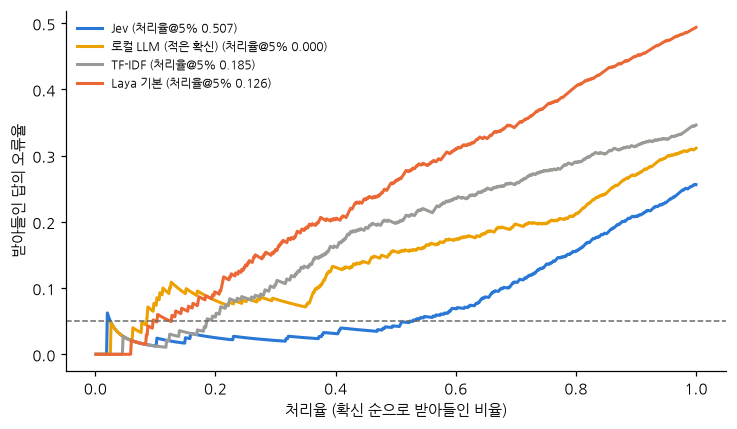

In [7]:
def risk_curve(rs):
    conf, ok = arrays(rs)
    order = np.argsort(-conf, kind="stable")
    k = np.arange(1, len(conf) + 1)
    return k / len(conf), np.cumsum(1 - ok[order]) / k

def coverage_at_risk(conf, ok, risk=0.05):
    order = np.argsort(-conf, kind="stable")
    c, y, k = conf[order], ok[order], np.arange(1, len(conf) + 1)
    return float(np.max(k[np.append(c[1:] != c[:-1], True) & (np.cumsum(1 - y) / k <= risk)], initial=0) / len(conf))

fig, ax = plt.subplots(figsize=(6.8, 4), dpi=110)
for (n, name), color in zip(ENGINES.items(), ["#2a78d6", "#eda100", "#9a9a96", "#eb6834"]):
    cov, risk = risk_curve(recs[n])
    ax.plot(cov, risk, lw=2, color=color, label=f"{name} (처리율@5% {coverage_at_risk(*arrays(recs[n])):.3f})")
ax.axhline(0.05, ls="--", lw=1, color="#6b6b66")
ax.set_xlabel("처리율 (확신 순으로 받아들인 비율)"); ax.set_ylabel("받아들인 답의 오류율"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "nb03_coverage_risk.png", bbox_inches="tight"); plt.show()

## 정리

이 노트북이 잰 것이다. 결과 해석은 3장 본문에서 한다.

- 3.2 Jev 와 로컬 LLM 기록의 구간별 항목 수·평균 확신·정답률과 ECE 계산
- 3.3 네 엔진의 신뢰도 도표
- 3.4 정확도·ECE·Brier·로그 손실
- 3.5 Murphy 분해(reliability·resolution·uncertainty), AUROC, 늘 같은 확신을 내는 가상 엔진
- 3.6 확신 순 처리율-오류율 곡선과 처리율@5%